In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import ttest_ind
from collections import defaultdict
import warnings
warnings.filterwarnings('ignore')

In [ ]:
class DroneEnv:
    def __init__(self, discrete=True):
        self.x_min, self.x_max = 0.0, 24.0
        self.y_min, self.y_max = 0.0, 12.0

        self.station_center = (21.5, 8.5)
        self.station_radius = 0.9
        self.charge_power = 0.025

        self.obstacles = [
            (10.0, 11.5, 2.0, 5.5),
            (13.0, 14.5, 7.0, 10.0),
            (16.5, 18.0, 3.5, 6.5),
            (19.0, 20.5, 9.0, 11.5)
        ]

        self.wind_update_period = 15
        self.wind_bounds = (-0.11, 0.11)
        self.wind = (0.0, 0.0)

        self.velocities = np.array([0.10, 0.25, 0.40, 0.60])

        self.actions = []
        for theta in [0, np.pi/2, np.pi, 3*np.pi/2]:
            for v in self.velocities[:3]:  # 0.10, 0.25, 0.40
                self.actions.append((theta, v))
        self.n_actions = len(self.actions)  # = 12

        self.n_dx = 14
        self.n_dy = 14
        self.n_b = 12
        self.n_v = 4
        self.state_bins = [self.n_dx, self.n_dy, self.n_b, self.n_v]

        self.discrete = discrete
        self.max_steps = 200
        self.success_threshold = 0.9
        self.success_battery = 0.50
        self.fail_battery = 0.10

        self.previous_distance = None

    def _discretize(self, dx, dy, b, v):
        dx_bin = min(self.n_dx-1, int((dx / 24.0) * self.n_dx))
        dy_bin = min(self.n_dy-1, int((dy / 12.0) * self.n_dy))
        b_bin = min(self.n_b-1, int(b * self.n_b))
        v_idx = np.argmin(np.abs(self.velocities - v))
        return (dx_bin, dy_bin, b_bin, v_idx)

    def _apply_collision(self, x, y, new_x, new_y):
        for ox1, ox2, oy1, oy2 in self.obstacles:
            if ox1 <= new_x <= ox2 and oy1 <= new_y <= oy2:
                left_dist = abs(new_x - ox1)
                right_dist = abs(new_x - ox2)
                bottom_dist = abs(new_y - oy1)
                top_dist = abs(new_y - oy2)
                min_d = min(left_dist, right_dist, bottom_dist, top_dist)
                if min_d == left_dist:
                    new_x = ox1
                elif min_d == right_dist:
                    new_x = ox2
                elif min_d == bottom_dist:
                    new_y = oy1
                else:
                    new_y = oy2
                break
        return np.clip(new_x, self.x_min, self.x_max), np.clip(new_y, self.y_min, self.y_max)

    def update_wind(self, step):
        if step % self.wind_update_period == 0:
            self.wind = (np.random.uniform(*self.wind_bounds),
                         np.random.uniform(*self.wind_bounds))

    def step(self, action_idx):
        theta, target_v = self.actions[action_idx]
        curr_v = self.velocities[self.v_idx]

        new_x = self.x + target_v * np.cos(theta) + self.wind[0]
        new_y = self.y + target_v * np.sin(theta) + self.wind[1]
        new_x, new_y = self._apply_collision(self.x, self.y, new_x, new_y)

        wind_norm = np.linalg.norm(self.wind)
        energy_cost = 0.018 * (target_v**2) + 0.003 * wind_norm + 0.002 * abs(target_v)
        new_b = self.b - energy_cost
        if self.in_station:
            new_b += self.charge_power
        new_b = np.clip(new_b, 0.0, 1.0)

        dist_to_station = np.hypot(new_x - self.station_center[0], new_y - self.station_center[1])
        success = (dist_to_station < self.station_radius and new_b >= self.success_battery and self.steps < self.max_steps)
        fail = (new_b < self.fail_battery) or (self.steps >= self.max_steps)
        done = success or fail

        if success:
            reward = 100.0
        elif fail and new_b < self.fail_battery:
            reward = -50.0
        else:
            in_station_now = (dist_to_station < self.station_radius)

            current_distance = dist_to_station
            distance_reward = (self.previous_distance - current_distance) * 2.0
            self.previous_distance = current_distance

            base_reward = -0.5 - 0.015 * (target_v**2)  # было -1.0 - 0.030

            station_bonus = 0.5 if in_station_now else 0.0

            reward = base_reward + distance_reward + station_bonus

        self.x, self.y = new_x, new_y
        self.b = new_b
        self.in_station = (dist_to_station < self.station_radius)
        self.v_idx = np.argmin(np.abs(self.velocities - target_v))
        self.steps += 1

        dx = self.station_center[0] - self.x
        dy = self.station_center[1] - self.y
        if self.discrete:
            state = self._discretize(dx, dy, self.b, self.velocities[self.v_idx])
        else:
            state = (dx, dy, self.b, self.velocities[self.v_idx])

        return state, reward, done, {'success': success, 'fail': fail}

    def reset(self):
        # Стартовая позиция: N((3.5,6), 1.8^2 I)
        self.x = np.clip(np.random.normal(3.5, 1.8), 1.0, 7.0)
        self.y = np.clip(np.random.normal(6.0, 1.8), 2.0, 10.0)
        self.b = 1.0
        self.v_idx = 1  # 0.25 (средняя)
        self.in_station = False
        self.steps = 0
        self.wind = (0.0, 0.0)
        dx = self.station_center[0] - self.x
        dy = self.station_center[1] - self.y
        self.previous_distance = np.hypot(self.x - self.station_center[0],
                                          self.y - self.station_center[1])
        return self._discretize(dx, dy, self.b, self.velocities[self.v_idx])

In [ ]:
class RationalQLearning:
    def __init__(self, n_states, n_actions, gamma=0.99, alpha=0.1, epsilon=1.0, epsilon_min=0.01, epsilon_decay=0.997):
        self.Q = defaultdict(lambda: np.zeros(n_actions))
        self.gamma = gamma
        self.alpha = alpha
        self.epsilon = epsilon
        self.epsilon_min = epsilon_min
        self.epsilon_decay = epsilon_decay
        self.n_actions = n_actions

    def act(self, state, training=True):
        if training and np.random.rand() < self.epsilon:
            return np.random.randint(self.n_actions)
        else:
            return np.argmax(self.Q[state])

    def update(self, state, action, reward, next_state, done):
        best_next = np.max(self.Q[next_state]) if not done else 0.0
        td_target = reward + self.gamma * best_next
        td_error = td_target - self.Q[state][action]
        self.Q[state][action] += self.alpha * td_error

    def decay_epsilon(self):
        self.epsilon = max(self.epsilon_min, self.epsilon * self.epsilon_decay)

In [ ]:
class ProspectTheoryQLearning(RationalQLearning):
    def __init__(self, n_states, n_actions, alpha_p=0.88, beta_p=0.88, lam=2.35, **kwargs):
        super().__init__(n_states, n_actions, **kwargs)
        self.alpha_p = alpha_p
        self.beta_p = beta_p
        self.lam = lam

    def value_function(self, r):
        if r >= 0:
            return r ** self.alpha_p
        else:
            return -self.lam * ((-r) ** self.beta_p)

    def update(self, state, action, reward, next_state, done):
        v_reward = self.value_function(reward)
        best_next = np.max(self.Q[next_state]) if not done else 0.0
        td_target = v_reward + self.gamma * best_next
        td_error = td_target - self.Q[state][action]
        self.Q[state][action] += self.alpha * td_error

In [ ]:
class FixedRiskSensitiveQLearning:
    def __init__(self, n_states, n_actions, eta=0.1, gamma=0.99, alpha=0.1,
                 epsilon=1.0, epsilon_min=0.01, epsilon_decay=0.997):
        self.U = defaultdict(lambda: np.ones(n_actions))
        self.eta = eta
        self.gamma = gamma
        self.alpha = alpha
        self.epsilon = epsilon
        self.epsilon_min = epsilon_min
        self.epsilon_decay = epsilon_decay
        self.n_actions = n_actions
        self.Q_cache = {}

    def Q_from_U(self, state):
        if state in self.Q_cache:
            return self.Q_cache[state]
        U_vals = np.maximum(self.U[state], 1e-6)
        Q_vals = -np.log(U_vals) / self.eta
        Q_vals = np.clip(Q_vals, -100, 100)
        self.Q_cache[state] = Q_vals
        return Q_vals

    def act(self, state, training=True):
        if training and np.random.rand() < self.epsilon:
            return np.random.randint(self.n_actions)
        Q_vals = self.Q_from_U(state)
        if np.any(np.isnan(Q_vals)) or np.any(np.isinf(Q_vals)):
            return np.random.randint(self.n_actions)
        return np.argmax(Q_vals)

    def update(self, state, action, reward, next_state, done):
        clipped_reward = np.clip(reward, -20, 20)
        exp_neg_eta_r = np.exp(-self.eta * clipped_reward)
        exp_neg_eta_r = np.clip(exp_neg_eta_r, 1e-6, 1e6)

        if not done:
            min_U_next = np.min(self.U[next_state])
            target = exp_neg_eta_r * (min_U_next ** self.gamma)
        else:
            target = exp_neg_eta_r

        target = np.clip(target, 1e-6, 1e6)
        self.U[state][action] += self.alpha * (target - self.U[state][action])
        self.U[state][action] = np.clip(self.U[state][action], 1e-6, 1e6)

        if state in self.Q_cache:
            del self.Q_cache[state]

    def decay_epsilon(self):
        self.epsilon = max(self.epsilon_min, self.epsilon * self.epsilon_decay)

In [ ]:
def train_agent(env, agent, n_episodes=15000, verbose=True):
    rewards_log = []
    success_log = []
    steps_log = []
    collisions_log = []
    final_battery_log = []

    for ep in range(n_episodes):
        state = env.reset()
        total_reward = 0.0
        steps = 0
        collisions = 0
        done = False

        while not done:
            action = agent.act(state, training=True)
            next_state, reward, done, info = env.step(action)
            agent.update(state, action, reward, next_state, done)
            state = next_state
            total_reward += reward
            steps += 1
            if info['fail'] and 'разряд' in str(info):  # условно считаем любой fail как столкновение с плохим исходом
                collisions += 1

        agent.decay_epsilon()
        rewards_log.append(total_reward)
        success_log.append(1 if info.get('success', False) else 0)
        steps_log.append(steps)
        collisions_log.append(collisions)
        final_battery_log.append(env.b)

        if verbose and (ep+1) % 1000 == 0:
            print(f"Episode {ep+1}/{n_episodes} | Reward: {total_reward:.1f} | Success: {success_log[-1]}")

    return {'rewards': rewards_log, 'success': success_log, 'steps': steps_log,
            'collisions': collisions_log, 'final_battery': final_battery_log}

In [ ]:
def test_agent(env, agent, n_episodes=300, epsilon_test=0.005):
    agent.epsilon = epsilon_test
    successes = []
    steps_to_success = []
    energy_consumption = []
    collisions = []

    for _ in range(n_episodes):
        state = env.reset()
        done = False
        initial_battery = env.b
        step_count = 0

        while not done:
            action = agent.act(state, training=False)
            next_state, reward, done, info = env.step(action)
            step_count += 1
            state = next_state

        successes.append(1 if info.get('success', False) else 0)
        if info.get('success', False):
            steps_to_success.append(step_count)

        energy_used = (initial_battery - env.b) * 100  # в процентах
        energy_consumption.append(max(0, energy_used))

        collisions.append(1 if info.get('fail', False) and not info.get('success', False) else 0)

    success_rate = np.mean(successes) * 100
    mean_time = np.mean(steps_to_success) if steps_to_success else np.nan
    mean_energy = np.mean(energy_consumption)
    collision_rate = np.mean(collisions) * 100

    return {
        'success_rate': success_rate,
        'mean_time_success': mean_time,
        'mean_energy': mean_energy,
        'collision_rate': collision_rate,
        'steps_to_success': steps_to_success,
        'energy_list': energy_consumption
    }

In [ ]:
def plot_learning_curves(data_dict, window=150):
    plt.figure(figsize=(12,5))
    for name, d in data_dict.items():
        rewards = d['train_log']['rewards']
        smoothed = np.convolve(rewards, np.ones(window)/window, mode='valid')
        plt.plot(smoothed, label=name)
    plt.xlabel('Episode'); plt.ylabel('Total Reward (smoothed)'); plt.legend(); plt.title('Learning curves'); plt.grid(True)
    plt.show()

def plot_cdf_time(data_dict):
    plt.figure(figsize=(8,5))
    for name, d in data_dict.items():
        times = d['test_results']['steps_to_success']
        if len(times) > 0:
            sorted_times = np.sort(times)
            y = np.arange(1, len(sorted_times)+1)/len(sorted_times)
            plt.plot(sorted_times, y, label=name)
    plt.xlabel('Time steps to success'); plt.ylabel('CDF'); plt.legend(); plt.title('Success time distribution'); plt.grid(True)
    plt.show()

def plot_battery_heatmap(data_dict, env):
    fig, axes = plt.subplots(1, 3, figsize=(15,5))
    for ax, (name, d) in zip(axes, data_dict.items()):
        battery = d['train_log']['final_battery']
        ax.hist(battery, bins=20, alpha=0.7, density=True)
        ax.set_title(f'{name}\nFinal battery')
        ax.set_xlabel('Battery level')
    plt.tight_layout()
    plt.show()

def plot_trajectories(env, agent, n_trajs=4, agent_name='Agent'):
    plt.figure(figsize=(10,6))
    for obs in env.obstacles:
        rect = plt.Rectangle((obs[0], obs[2]), obs[1]-obs[0], obs[3]-obs[2], fc='gray', alpha=0.5)
        plt.gca().add_patch(rect)
    station = plt.Circle(env.station_center, env.station_radius, color='green', alpha=0.5)
    plt.gca().add_patch(station)

    for ep in range(n_trajs):
        state = env.reset()
        done = False
        xs, ys = [env.x], [env.y]
        while not done:
            action = agent.act(state, training=False)
            state, _, done, _ = env.step(action)
            xs.append(env.x); ys.append(env.y)
        plt.plot(xs, ys, alpha=0.7, label=f'Traj {ep+1}')
    plt.xlim(env.x_min, env.x_max); plt.ylim(env.y_min, env.y_max)
    plt.title(f'Trajectories - {agent_name}')
    plt.xlabel('x'); plt.ylabel('y'); plt.legend()
    plt.show()


--- Training Rational ---
Episode 1000/15000 | Reward: 105.4 | Success: 1
Episode 2000/15000 | Reward: 98.7 | Success: 1
Episode 3000/15000 | Reward: 109.8 | Success: 1
Episode 4000/15000 | Reward: 111.2 | Success: 1
Episode 5000/15000 | Reward: 105.6 | Success: 1
Episode 6000/15000 | Reward: 109.3 | Success: 1
Episode 7000/15000 | Reward: 109.8 | Success: 1
Episode 8000/15000 | Reward: 107.4 | Success: 1
Episode 9000/15000 | Reward: 107.6 | Success: 1
Episode 10000/15000 | Reward: 102.1 | Success: 1
Episode 11000/15000 | Reward: 103.0 | Success: 1
Episode 12000/15000 | Reward: 103.9 | Success: 1
Episode 13000/15000 | Reward: 109.1 | Success: 1
Episode 14000/15000 | Reward: 106.3 | Success: 1
Episode 15000/15000 | Reward: 90.4 | Success: 1

--- Training ProspectTheory ---
Episode 1000/15000 | Reward: 107.1 | Success: 1
Episode 2000/15000 | Reward: 106.4 | Success: 1
Episode 3000/15000 | Reward: 100.9 | Success: 1
Episode 4000/15000 | Reward: 107.4 | Success: 1
Episode 5000/15000 | Rew

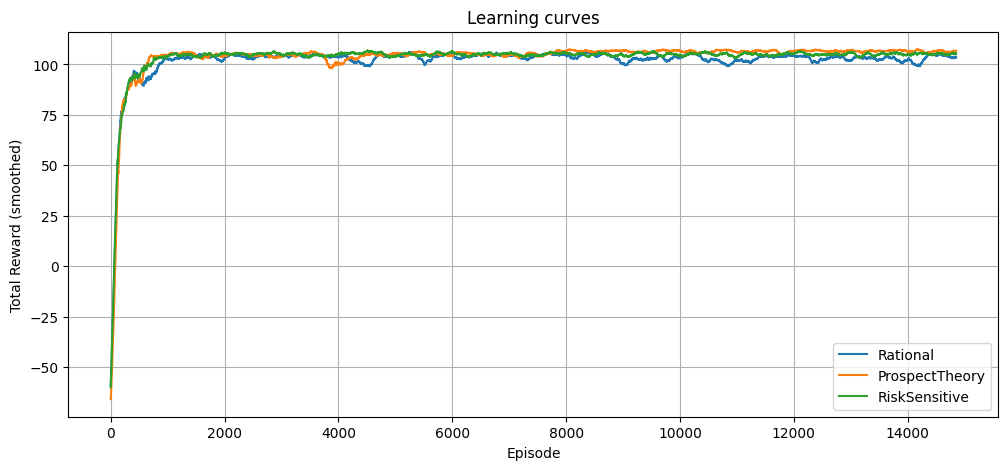

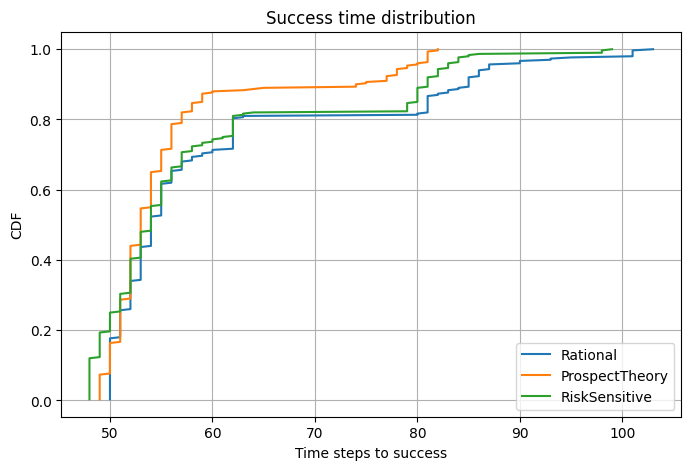

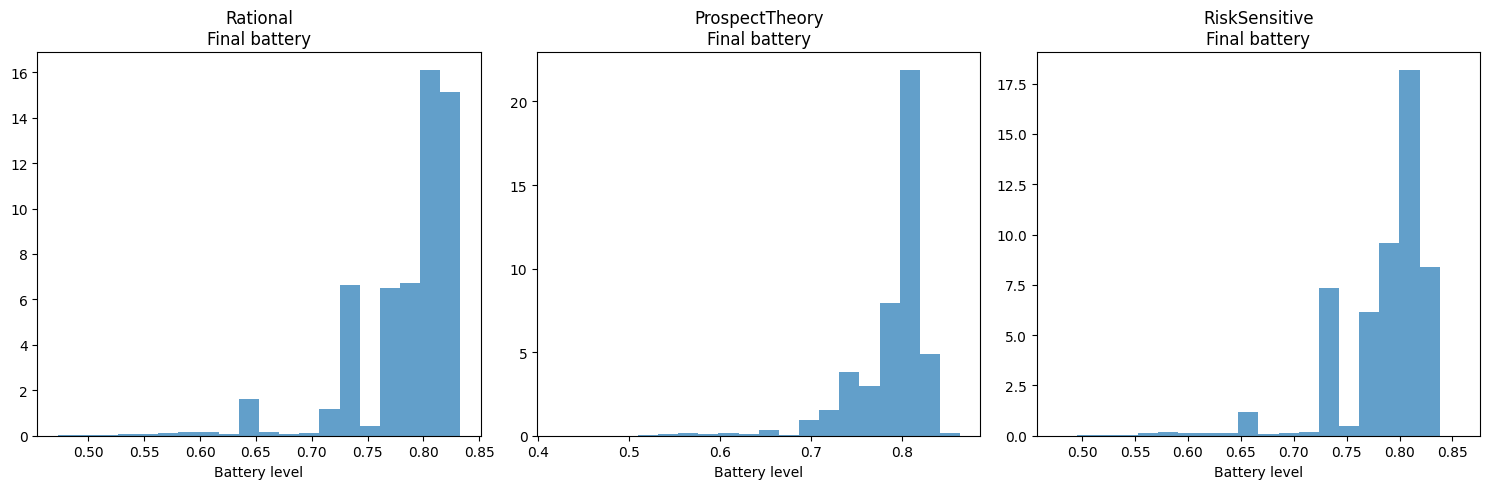

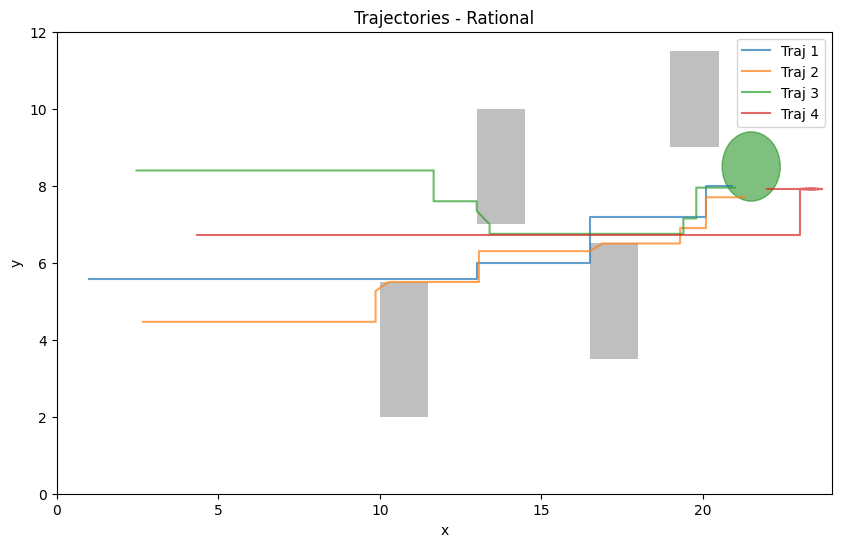

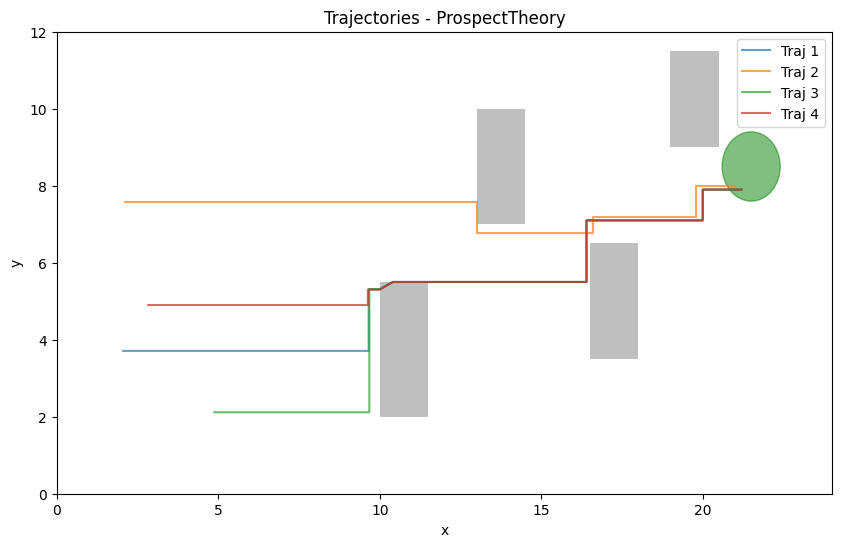

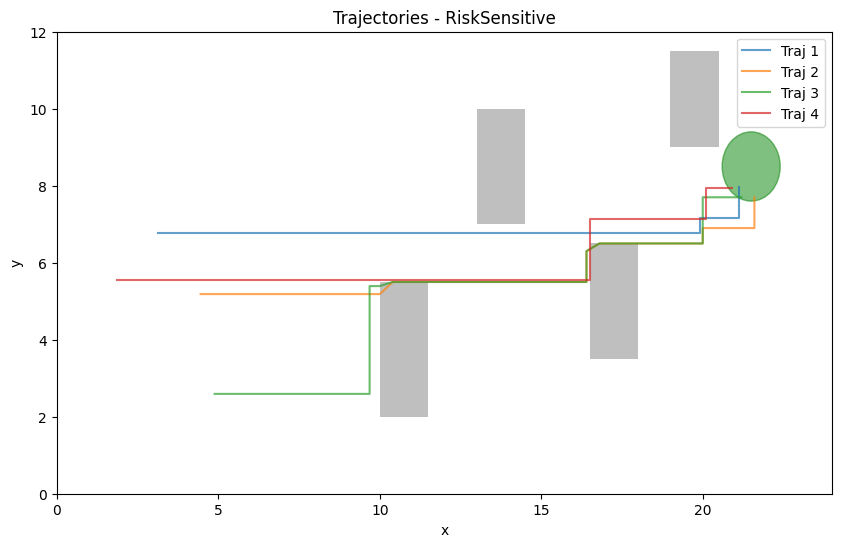

(t-test, p<0.05)
Rational vs Prospect: t=4.623, p=0.00000 -> different
Rational vs RiskSensitive: t=1.613, p=0.10727 -> same


In [ ]:
if __name__ == "__main__":
    env = DroneEnv(discrete=True)
    n_states = env.n_dx * env.n_dy * env.n_b * env.n_v
    n_actions = env.n_actions

    n_episodes = 15000
    gamma = 0.99
    alpha = 0.1

    rational = RationalQLearning(n_states, n_actions, gamma=gamma, alpha=alpha, epsilon=1.0, epsilon_min=0.01, epsilon_decay=0.997)
    prospect = ProspectTheoryQLearning(n_states, n_actions, gamma=gamma, alpha=alpha, epsilon=1.0, epsilon_min=0.01, epsilon_decay=0.997)
    risk = FixedRiskSensitiveQLearning(
        n_states, n_actions,
        eta=0.1,
        gamma=0.99,
        alpha=0.05,
        epsilon=1.0,
        epsilon_min=0.01,
        epsilon_decay=0.997
    )

    agents = {'Rational': rational, 'ProspectTheory': prospect, 'RiskSensitive': risk}

    train_logs = {}
    for name, agent in agents.items():
        print(f"\n--- Training {name} ---")
        env = DroneEnv(discrete=True)
        train_logs[name] = train_agent(env, agent, n_episodes=n_episodes, verbose=True)

    test_results = {}
    for name, agent in agents.items():
        env = DroneEnv(discrete=True)
        agent.epsilon = 0.005
        test_results[name] = test_agent(env, agent, n_episodes=300, epsilon_test=0.005)
        print(f"{name}: Success={test_results[name]['success_rate']:.1f}%, Time={test_results[name]['mean_time_success']:.1f}, Collisions={test_results[name]['collision_rate']:.1f}%")

    full_data = {}
    for name in agents:
        full_data[name] = {'train_log': train_logs[name], 'test_results': test_results[name]}

    plot_learning_curves(full_data, window=150)
    plot_cdf_time(full_data)
    plot_battery_heatmap(full_data, env)

    for name, agent in agents.items():
        env = DroneEnv(discrete=True)
        agent.epsilon = 0.005
        plot_trajectories(env, agent, n_trajs=4, agent_name=name)

    print("(t-test, p<0.05)")
    times_rational = test_results['Rational']['steps_to_success']
    times_prospect = test_results['ProspectTheory']['steps_to_success']
    times_risk = test_results['RiskSensitive']['steps_to_success']

    if len(times_rational) > 0 and len(times_prospect) > 0:
        t_stat, p_val = ttest_ind(times_rational, times_prospect, equal_var=False)
        print(f"Rational vs Prospect: t={t_stat:.3f}, p={p_val:.5f} -> {'different' if p_val<0.05 else 'same'}")
    if len(times_rational) > 0 and len(times_risk) > 0:
        t_stat, p_val = ttest_ind(times_rational, times_risk, equal_var=False)
        print(f"Rational vs RiskSensitive: t={t_stat:.3f}, p={p_val:.5f} -> {'different' if p_val<0.05 else 'same'}")